# Vellozia PPI Network Analysis via STRING-db API
Este notebook utiliza a API REST do STRING para obter as interações proteína-proteína (PPI) dos genes OSCA de *Vellozia peripherica* e *Vellozia tubiflora*.

Como as espécies foram mapeadas de forma customizada na versão 12, utilizaremos os IDs customizados do banco:
- *V. peripherica*: `STRG0A77QVI`
- *V. tubiflora*: `STRG0A11TDW`


In [1]:
import os
import requests
import pandas as pd
from io import StringIO
from IPython.display import Image, display

# Definir os diretórios
BASE_DIR = "/home/mfcaval/github/doutorado"
RESULTS_DIR = os.path.join(BASE_DIR, "analyses/07_ppi_network/results")
OSCA_IDS_FILE = os.path.join(BASE_DIR, "analyses/01_gene_identification/results/oscasIDs.txt")

os.makedirs(RESULTS_DIR, exist_ok=True)


## 1. Parâmetros da Análise
Altere a variável `TARGET_SPECIES` para alternar entre as espécies.
O parâmetro `ADD_NODES` determina quantas proteínas extras (parceiros de interação) o STRING vai adicionar à rede para além dos OSCAs informados.


In [2]:
# Parâmetros Flexíveis
TARGET_SPECIES = "Vper" # Mude para "Vtub" para rodar para Vellozia tubiflora

STRING_SPECIES_IDS = {
    "Vper": "STRG0A77QVI",
    "Vtub": "STRG0A11TDW"
}

# Parâmetros da API
STRING_API_URL = "https://string-db.org/api"
OUTPUT_FORMAT_TSV = "tsv"
OUTPUT_FORMAT_IMAGE = "highres_image"

SPECIES_ID = STRING_SPECIES_IDS[TARGET_SPECIES]
REQUIRED_SCORE = 400     # 400 = Confiança média (medium confidence)
ADD_NODES = 50           # Quantidade de parceiros de interação para adicionar na rede
NETWORK_TYPE = "functional" # 'functional' (conhecidas e previstas) ou 'physical'


## 2. Carregar os IDs Originais
Vamos ler o arquivo `oscasIDs.txt` e filtrar apenas os IDs correspondentes à espécie selecionada.


In [3]:
# Ler os IDs originais
original_ids = []

with open(OSCA_IDS_FILE, 'r') as f:
    for line in f:
        line = line.strip()
        if not line: continue
        orig_id, osca_name = line.split()
        
        # Filtrar pela espécie atual (Vper.hapA... ou Vtub.hapA...)
        if orig_id.startswith(TARGET_SPECIES):
            original_ids.append(orig_id)

print(f"Encontrados {len(original_ids)} genes para {TARGET_SPECIES}:")
print(original_ids)


Encontrados 14 genes para Vper:
['Vper.hapA.v1.chr4A.g117080.t1', 'Vper.hapA.v1.chr9A.g255760.t1', 'Vper.hapA.v1.chr7A.g186390.t1', 'Vper.hapA.v1.chr7A.g186400.t1', 'Vper.hapA.v1.chr7A.g186410.t1', 'Vper.hapA.v1.chr5A.g140750.t1', 'Vper.hapA.v1.chr1A.g021690.t1', 'Vper.hapA.v1.chr1A.g013600.t1', 'Vper.hapA.v1.chr1A.g023030.t1', 'Vper.hapA.v1.chr1A.g023020.t1', 'Vper.hapA.v1.chr9A.g257040.t1', 'Vper.hapA.v1.chr1A.g020450.t1', 'Vper.hapA.v1.chr5A.g142080.t1', 'Vper.hapA.v1.chr8A.g231320.t1']


## 3. Consultar a Rede de Interações (TSV)
Consultando o endpoint `/network` do STRING. Como você quer ver as interações dos OSCAs (e não apenas entre eles), a API retornará os parceiros de interação com maior score até o limite de `ADD_NODES`.


In [4]:
# Montar a requisição
request_url = f"{STRING_API_URL}/{OUTPUT_FORMAT_TSV}/network"

params = {
    "identifiers": "%0d".join(original_ids), # IDs separados por carriage return
    "species": SPECIES_ID,                   # ID mapeado no STRING
    "required_score": REQUIRED_SCORE,
    "add_nodes": ADD_NODES,
    "network_type": NETWORK_TYPE,
    "caller_identity": "doutorado_mfcaval"   # Boa prática colocar uma identificação
}

print("Consultando a API do STRING-db (dados em texto)...")
response = requests.post(request_url, data=params)

if response.status_code == 200:
    # Ler os dados TSV usando o pandas
    df_network = pd.read_csv(StringIO(response.text), sep='	')
    print(f"Rede retornada com {len(df_network)} interações (arestas).")
    display(df_network.head())
    
    # Salvar em disco
    tsv_path = os.path.join(RESULTS_DIR, f"{TARGET_SPECIES}_ppi_network.tsv")
    df_network.to_csv(tsv_path, sep='	', index=False)
    print(f"✅ Dados salvos em: {tsv_path}")
else:
    print(f"❌ Erro na consulta da API (Status {response.status_code})")
    print(response.text)


Consultando a API do STRING-db (dados em texto)...
Rede retornada com 187 interações (arestas).


,stringId_A,stringId_B,preferredName_A,preferredName_B,ncbiTaxonId,score,nscore,fscore,pscore,ascore,escore,dscore,tscore
0,STRG0A77QVI.Vper.hapA.v1.chr1A.g000610.t1,STRG0A77QVI.Vper.hapA.v1.chr1A.g020450.t1,Vper.hapA.v1.chr1A.g000610.t1,Vper.hapA.v1.chr1A.g020450.t1,STRG0A77QVI,0.416,0.0,0,0.0,0.0,0.0,0.0,0.416
1,STRG0A77QVI.Vper.hapA.v1.chr1A.g000610.t1,STRG0A77QVI.Vper.hapA.v1.chr5A.g142080.t1,Vper.hapA.v1.chr1A.g000610.t1,Vper.hapA.v1.chr5A.g142080.t1,STRG0A77QVI,0.416,0.0,0,0.0,0.0,0.0,0.0,0.416
2,STRG0A77QVI.Vper.hapA.v1.chr1A.g009900.t1,STRG0A77QVI.Vper.hapA.v1.chr8A.g231320.t1,Vper.hapA.v1.chr1A.g009900.t1,Vper.hapA.v1.chr8A.g231320.t1,STRG0A77QVI,0.430,0.0,0,0.0,0.0,0.0,0.0,0.430
3,STRG0A77QVI.Vper.hapA.v1.chr1A.g011000.t1,STRG0A77QVI.Vper.hapA.v1.chr2A.g069100.t1,Vper.hapA.v1.chr1A.g011000.t1,Vper.hapA.v1.chr2A.g069100.t1,STRG0A77QVI,0.604,0.0,0,0.0,0.0,0.0,0.0,0.604
4,STRG0A77QVI.Vper.hapA.v1.chr1A.g011000.t1,STRG0A77QVI.Vper.hapA.v1.chr7A.g186730.t1,Vper.hapA.v1.chr1A.g011000.t1,Vper.hapA.v1.chr7A.g186730.t1,STRG0A77QVI,0.594,0.0,0,0.0,0.0,0.0,0.0,0.594


✅ Dados salvos em: /home/mfcaval/github/doutorado/analyses/07_ppi_network/results/Vper_ppi_network.tsv


## 4. Gerar e Visualizar a Imagem da Rede
A API também permite baixar a representação visual da rede.


Consultando a API do STRING-db (imagem)...
✅ Imagem salva em: /home/mfcaval/github/doutorado/analyses/07_ppi_network/results/Vper_ppi_network.png


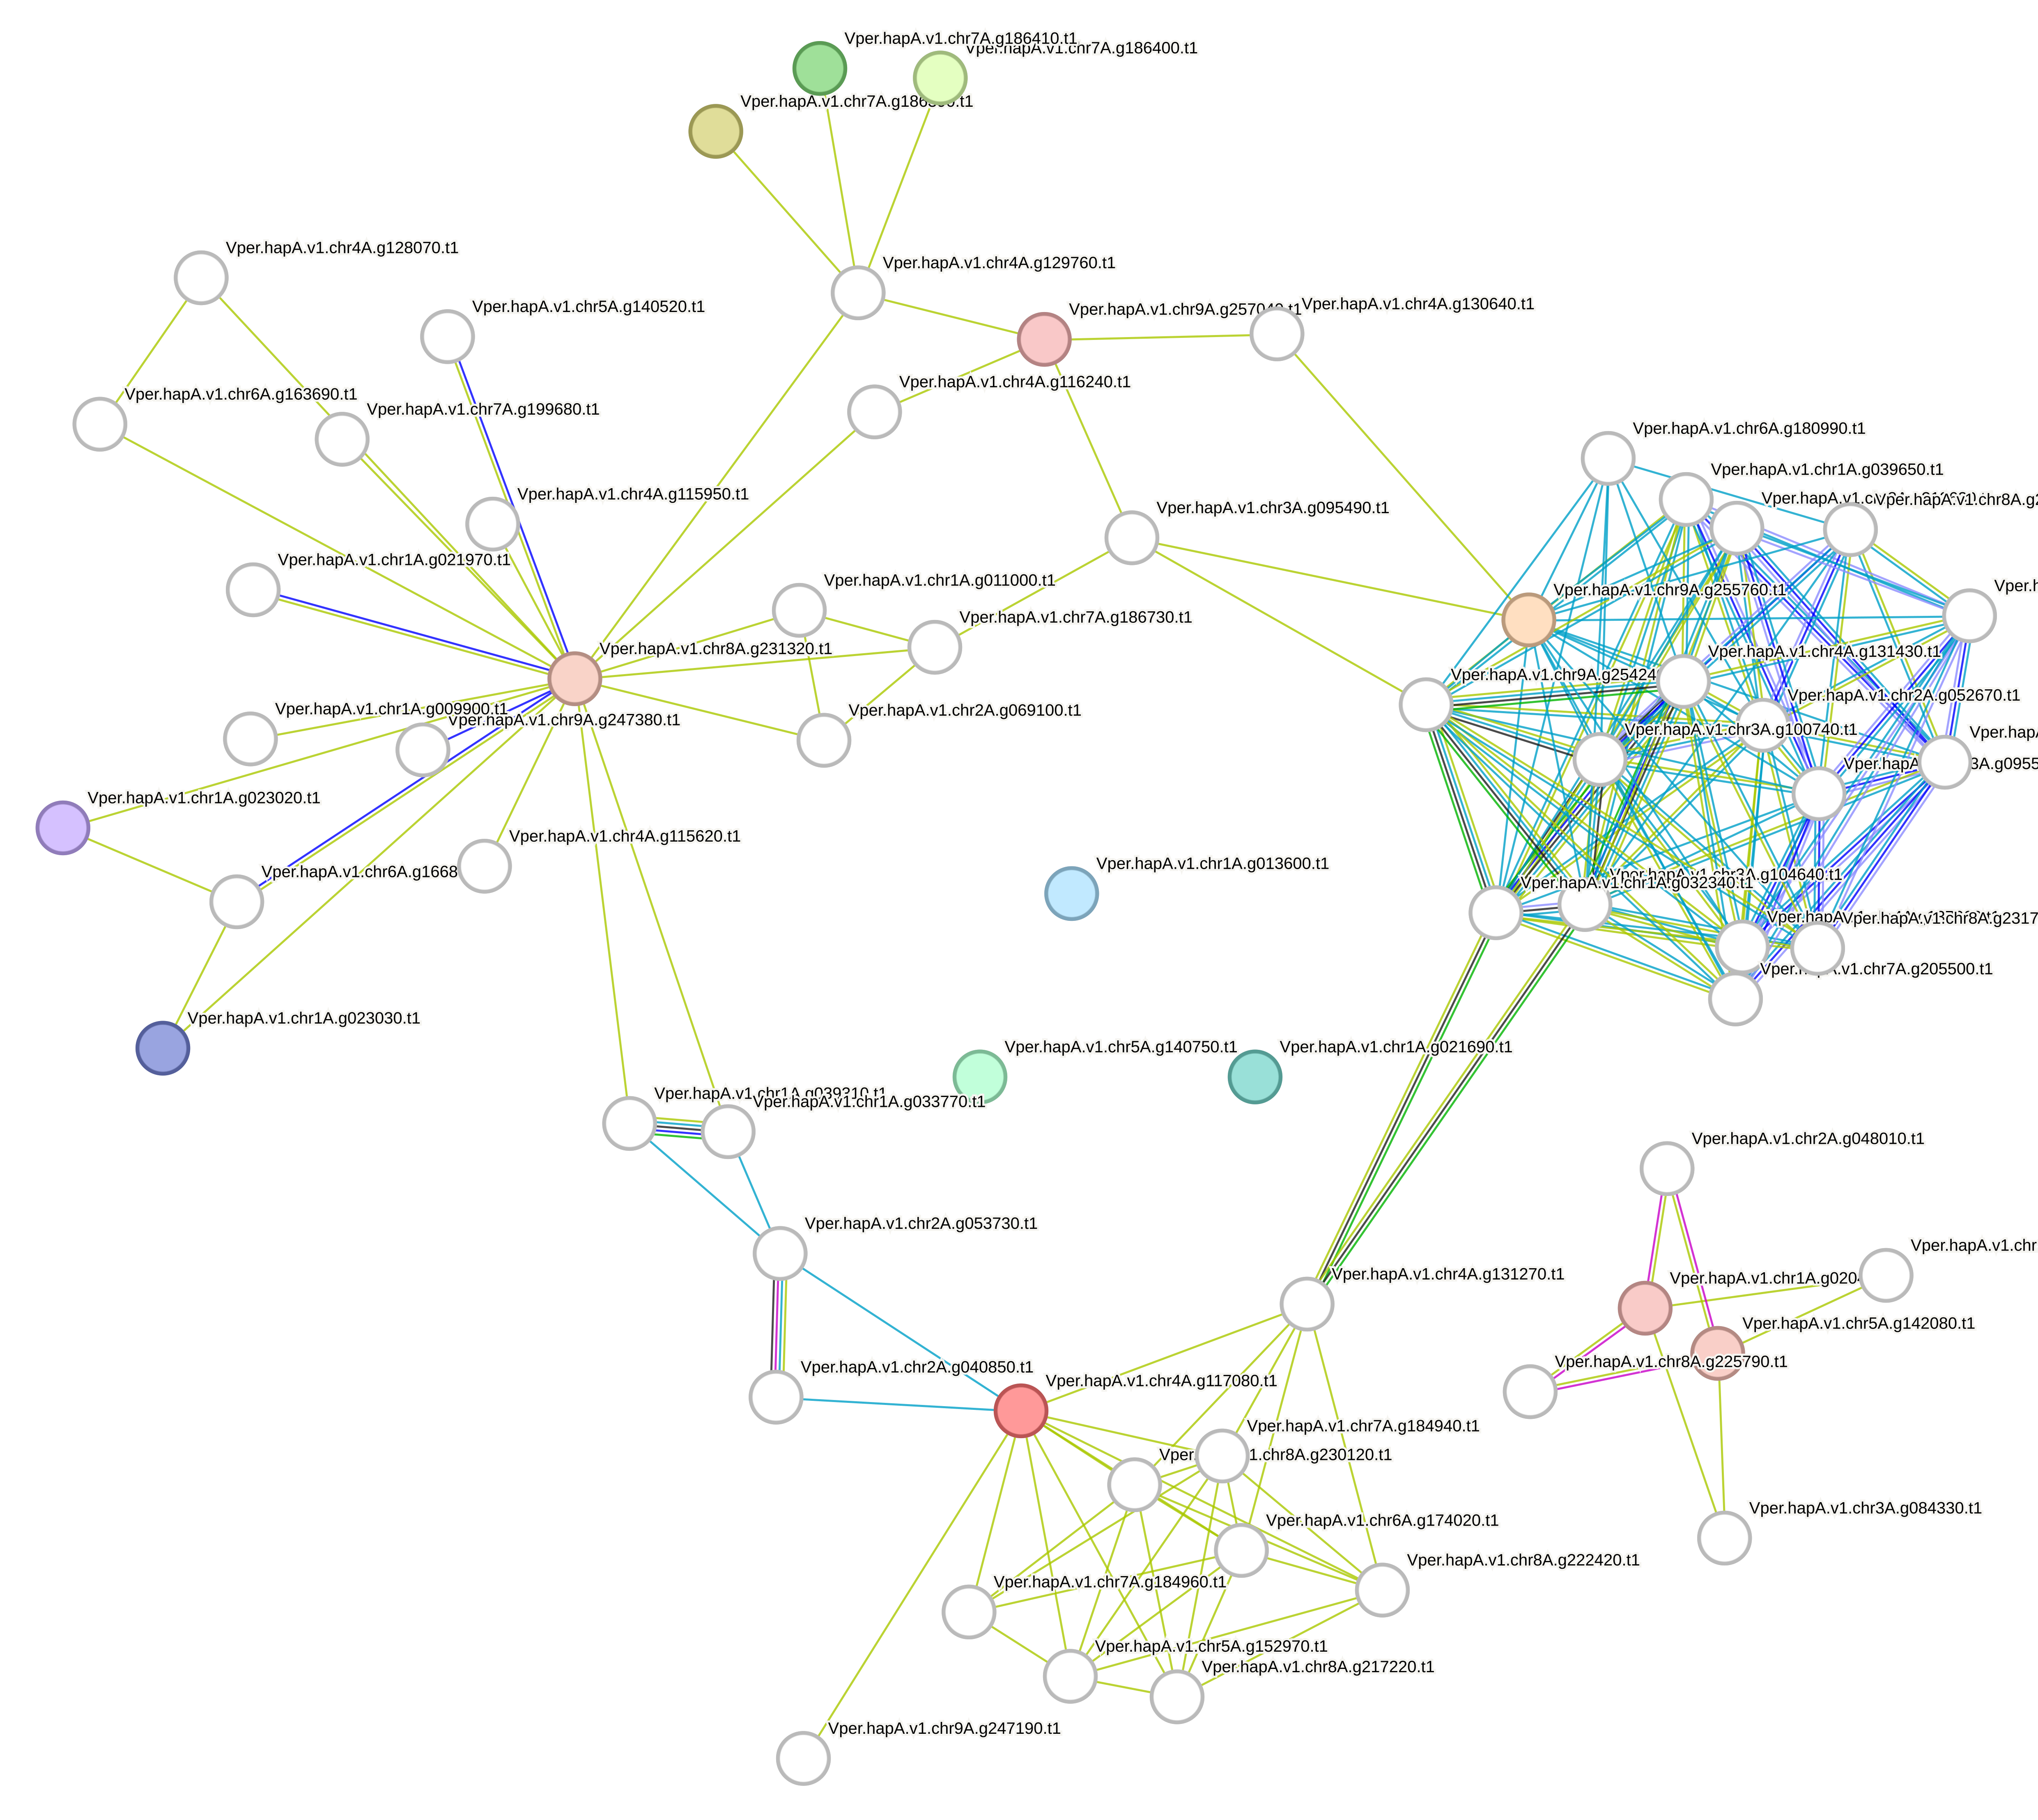

In [5]:
# Requisitar a imagem de alta resolução
image_url = f"{STRING_API_URL}/{OUTPUT_FORMAT_IMAGE}/network"

print("Consultando a API do STRING-db (imagem)...")
img_response = requests.post(image_url, data=params)

if img_response.status_code == 200:
    img_path = os.path.join(RESULTS_DIR, f"{TARGET_SPECIES}_ppi_network.png")
    
    with open(img_path, 'wb') as f:
        f.write(img_response.content)
    
    print(f"✅ Imagem salva em: {img_path}")
    
    # Exibir a imagem gerada no próprio notebook
    display(Image(filename=img_path))
else:
    print(f"❌ Erro ao baixar imagem (Status {img_response.status_code})")
    print(img_response.text)


## 5. Visualização Customizada com NetworkX
Agora vamos utilizar o `networkx` e o `matplotlib` para gerar uma visualização estilizada a partir do arquivo TSV salvo no passo 3. Essa rede ajusta o tamanho e a cor dos nós com base no número de conexões (grau).

Mantendo 187 arestas com score >= 0.4


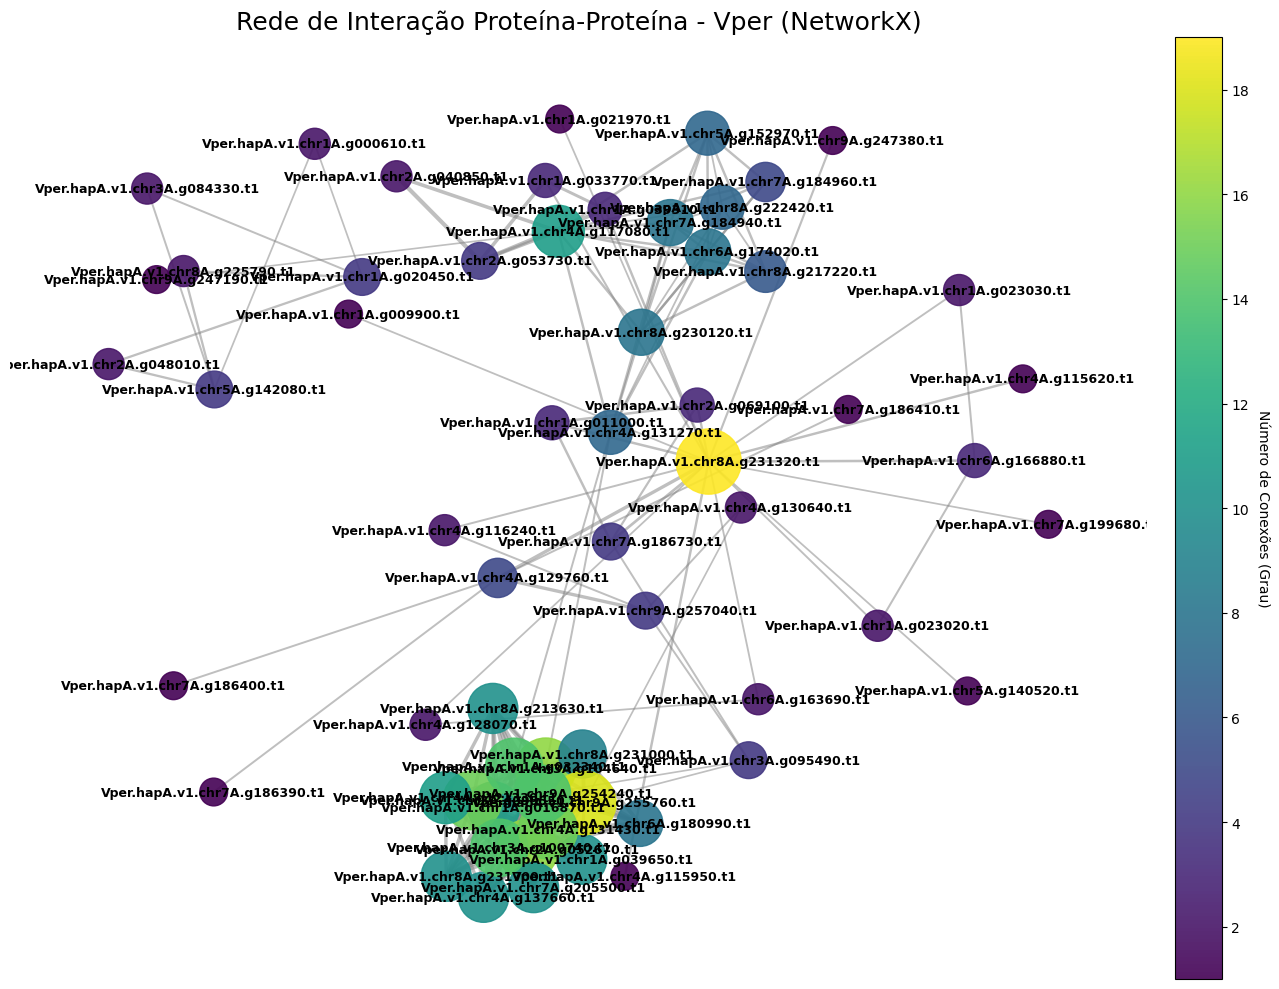

✅ Imagem NetworkX salva em: /home/mfcaval/github/doutorado/analyses/07_ppi_network/results/Vper_networkx.png


In [7]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

tsv_file = os.path.join(RESULTS_DIR, f"{TARGET_SPECIES}_ppi_network.tsv")
out_img_nx = os.path.join(RESULTS_DIR, f"{TARGET_SPECIES}_networkx.png")

if os.path.exists(tsv_file):
    df = pd.read_csv(tsv_file, sep="\t")
    
    # Filtrar usando a mesma variável de confiança já definida no começo
    df_filtered = df[df['score'] >= (REQUIRED_SCORE / 1000.0)]
    print(f"Mantendo {len(df_filtered)} arestas com score >= {REQUIRED_SCORE/1000.0}")

    # Construção do Grafo
    G = nx.Graph()
    for _, row in df_filtered.iterrows():
        node_a = row.get("preferredName_A", row["stringId_A"])
        node_b = row.get("preferredName_B", row["stringId_B"])
        G.add_edge(node_a, node_b, weight=row["score"])

    # Métricas para estilização
    degrees = dict(G.degree())
    node_sizes = [v * 100 + 300 for v in degrees.values()]
    edge_weights = nx.get_edge_attributes(G, 'weight')
    edge_widths = [weight * 3 for weight in edge_weights.values()]
    node_colors = list(degrees.values())

    # Renderização
    plt.figure(figsize=(14, 10))
    plt.title(f"Rede de Interação Proteína-Proteína - {TARGET_SPECIES} (NetworkX)", fontsize=18)
    
    pos = nx.spring_layout(G, k=0.5, seed=42)
    nodes = nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, cmap=plt.cm.viridis, alpha=0.9)
    nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.5, edge_color="gray")
    nx.draw_networkx_labels(G, pos, font_size=9, font_family="sans-serif", font_weight="bold")

    cbar = plt.colorbar(nodes, pad=0.02)
    cbar.set_label('Número de Conexões (Grau)', rotation=270, labelpad=15)

    plt.axis("off")
    plt.tight_layout()
    plt.savefig(out_img_nx, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"✅ Imagem NetworkX salva em: {out_img_nx}")
else:
    print("Execute as células anteriores para gerar o arquivo TSV primeiro!")


## 6. Recuperar Anotação Funcional (Functional Annotation)
Podemos consultar a API do STRING para obter a anotação funcional (GO, Pfam, InterPro, etc.) dos genes que compõem a nossa rede. Para isso, vamos extrair todos os nós (proteínas) únicos do TSV gerado e consultar o endpoint `/functional_annotation`.

In [8]:
import os
import requests
import pandas as pd
from io import StringIO

# Extrair todos os nós únicos da rede (usando o df_filtered da etapa 5)
unique_nodes = set(df_filtered['stringId_A']).union(set(df_filtered['stringId_B']))
unique_nodes = list(unique_nodes)
print(f"Total de proteínas únicas na rede: {len(unique_nodes)}")

# Montar requisição para anotação funcional
annot_url = f"{STRING_API_URL}/{OUTPUT_FORMAT_TSV}/functional_annotation"

params_annot = {
    "identifiers": "%0d".join(unique_nodes),
    "species": SPECIES_ID,
    "caller_identity": "doutorado_mfcaval"
}

print("Consultando a API para anotação funcional...")
resp_annot = requests.post(annot_url, data=params_annot)

if resp_annot.status_code == 200:
    df_annot = pd.read_csv(StringIO(resp_annot.text), sep='\t')
    print(f"Retornadas {len(df_annot)} anotações funcionais.")
    display(df_annot.head())
    
    # Salvar em disco
    annot_path = os.path.join(RESULTS_DIR, f"{TARGET_SPECIES}_functional_annotation.tsv")
    df_annot.to_csv(annot_path, sep='\t', index=False)
    print(f"✅ Anotações funcionais salvas em: {annot_path}")
else:
    print(f"❌ Erro na consulta (Status {resp_annot.status_code})")
    print(resp_annot.text)


Total de proteínas únicas na rede: 61
Consultando a API para anotação funcional...
Retornadas 1040 anotações funcionais.


,category,term,number_of_genes,ratio_in_set,ncbiTaxonId,inputGenes,preferredNames,description
0,COMPARTMENTS,GOCC:0000325,1,0.016,110056455,STRG0A77QVI.Vper.hapA.v1.chr1A.g000610.t1,Vper.hapA.v1.chr1A.g000610.t1,Plant-type vacuole
1,COMPARTMENTS,GOCC:0000407,1,0.016,110056455,STRG0A77QVI.Vper.hapA.v1.chr9A.g247190.t1,Vper.hapA.v1.chr9A.g247190.t1,Phagophore assembly site
2,COMPARTMENTS,GOCC:0000793,2,0.033,110056455,"STRG0A77QVI.Vper.hapA.v1.chr2A.g040850.t1,STRG...","Vper.hapA.v1.chr2A.g040850.t1,Vper.hapA.v1.chr...",Condensed chromosome
3,COMPARTMENTS,GOCC:0000796,2,0.033,110056455,"STRG0A77QVI.Vper.hapA.v1.chr2A.g040850.t1,STRG...","Vper.hapA.v1.chr2A.g040850.t1,Vper.hapA.v1.chr...",Condensin complex
4,COMPARTMENTS,GOCC:0005576,3,0.049,110056455,"STRG0A77QVI.Vper.hapA.v1.chr2A.g052670.t1,STRG...","Vper.hapA.v1.chr2A.g052670.t1,Vper.hapA.v1.chr...",Extracellular region


✅ Anotações funcionais salvas em: /home/mfcaval/github/doutorado/analyses/07_ppi_network/results/Vper_functional_annotation.tsv


In [21]:
df_annot['category'].value_counts()

df_annot[df_annot['category'] == 'KEGG'].sort_values('ratio_in_set', ascending=False)

,category,term,number_of_genes,ratio_in_set,ncbiTaxonId,inputGenes,preferredNames,description
805,KEGG,map01100,30,0.492,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g016870.t1,STRG...","Vper.hapA.v1.chr1A.g016870.t1,Vper.hapA.v1.chr...",Metabolic pathways
806,KEGG,map01110,29,0.475,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g016870.t1,STRG...","Vper.hapA.v1.chr1A.g016870.t1,Vper.hapA.v1.chr...",Biosynthesis of secondary metabolites
800,KEGG,map00500,22,0.361,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g016870.t1,STRG...","Vper.hapA.v1.chr1A.g016870.t1,Vper.hapA.v1.chr...",Starch and sucrose metabolism
799,KEGG,map00350,3,0.049,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g033770.t1,STRG...","Vper.hapA.v1.chr1A.g033770.t1,Vper.hapA.v1.chr...",Tyrosine metabolism
809,KEGG,map03013,3,0.049,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g021970.t1,STRG...","Vper.hapA.v1.chr1A.g021970.t1,Vper.hapA.v1.chr...",RNA transport
807,KEGG,map02010,3,0.049,110056455,"STRG0A77QVI.Vper.hapA.v1.chr4A.g115620.t1,STRG...","Vper.hapA.v1.chr4A.g115620.t1,Vper.hapA.v1.chr...",ABC transporters
814,KEGG,map04626,2,0.033,110056455,"STRG0A77QVI.Vper.hapA.v1.chr2A.g048010.t1,STRG...","Vper.hapA.v1.chr2A.g048010.t1,Vper.hapA.v1.chr...",Plant-pathogen interaction
798,KEGG,map00195,1,0.016,110056455,STRG0A77QVI.Vper.hapA.v1.chr3A.g084330.t1,Vper.hapA.v1.chr3A.g084330.t1,Photosynthesis
803,KEGG,map00790,1,0.016,110056455,STRG0A77QVI.Vper.hapA.v1.chr7A.g199680.t1,Vper.hapA.v1.chr7A.g199680.t1,Folate biosynthesis
802,KEGG,map00670,1,0.016,110056455,STRG0A77QVI.Vper.hapA.v1.chr7A.g199680.t1,Vper.hapA.v1.chr7A.g199680.t1,One carbon pool by folate


## 7. Análise de Enriquecimento (Enrichment Analysis)
Além das anotações individuais, podemos verificar quais termos (GO, vias KEGG, domínios) estão estatisticamente enriquecidos nesse conjunto de proteínas quando comparados ao genoma completo, usando o endpoint `/enrichment`.

In [9]:
enrich_url = f"{STRING_API_URL}/{OUTPUT_FORMAT_TSV}/enrichment"

print("Consultando a API para análise de enriquecimento...")
resp_enrich = requests.post(enrich_url, data=params_annot)

if resp_enrich.status_code == 200:
    df_enrich = pd.read_csv(StringIO(resp_enrich.text), sep='\t')
    print(f"Encontrados {len(df_enrich)} termos enriquecidos.")
    display(df_enrich.head())
    
    # Salvar em disco
    enrich_path = os.path.join(RESULTS_DIR, f"{TARGET_SPECIES}_enrichment.tsv")
    df_enrich.to_csv(enrich_path, sep='\t', index=False)
    print(f"✅ Resultados do enriquecimento salvos em: {enrich_path}")
else:
    print(f"❌ Erro na consulta (Status {resp_enrich.status_code})")
    print(resp_enrich.text)


Consultando a API para análise de enriquecimento...
Encontrados 84 termos enriquecidos.


,category,term,number_of_genes,number_of_genes_in_background,ncbiTaxonId,inputGenes,preferredNames,p_value,fdr,description
0,COMPARTMENTS,GOCC:0071944,16,1548,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g020450.t1,STRG...","Vper.hapA.v1.chr1A.g020450.t1,Vper.hapA.v1.chr...",3.190000e-07,0.00029,Cell periphery
1,COMPARTMENTS,GOCC:1903440,3,3,110056455,"STRG0A77QVI.Vper.hapA.v1.chr2A.g052670.t1,STRG...","Vper.hapA.v1.chr2A.g052670.t1,Vper.hapA.v1.chr...",2.300000e-07,0.00029,Amylin receptor complex
2,COMPARTMENTS,GOCC:0005886,13,1201,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g020450.t1,STRG...","Vper.hapA.v1.chr1A.g020450.t1,Vper.hapA.v1.chr...",3.060000e-06,0.00078,Plasma membrane
3,COMPARTMENTS,GOCC:0016020,21,3553,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g000610.t1,STRG...","Vper.hapA.v1.chr1A.g000610.t1,Vper.hapA.v1.chr...",2.630000e-05,0.00560,Membrane
4,COMPARTMENTS,GOCC:0110165,57,19154,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g000610.t1,STRG...","Vper.hapA.v1.chr1A.g000610.t1,Vper.hapA.v1.chr...",3.690000e-05,0.00560,Cellular anatomical entity


✅ Resultados do enriquecimento salvos em: /home/mfcaval/github/doutorado/analyses/07_ppi_network/results/Vper_enrichment.tsv


In [ ]:
df_enrich[df_enrich['category'] == "NetworkNeighborAL"].to_csv('/home/mfcaval/github/doutorado/analyses/07_ppi_network/results/Vper_NetworkNeighborAL.tsv', sep = '/t', index = False)

,category,term,number_of_genes,number_of_genes_in_background,ncbiTaxonId,inputGenes,preferredNames,p_value,fdr,description
73,NetworkNeighborAL,CL:11507,17,40,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g016870.t1,STRG...","Vper.hapA.v1.chr1A.g016870.t1,Vper.hapA.v1.chr...",1.580000e-32,8.110000e-29,"Starch metabolic process, and Amylopectin malt..."
74,NetworkNeighborAL,CL:11549,15,19,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g016870.t1,STRG...","Vper.hapA.v1.chr1A.g016870.t1,Vper.hapA.v1.chr...",7.350000e-32,1.890000e-28,"Amylase activity, and Isoamylase activity"
75,NetworkNeighborAL,CL:19052,11,16,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g023020.t1,STRG...","Vper.hapA.v1.chr1A.g023020.t1,Vper.hapA.v1.chr...",4.630000e-23,3.970000e-20,"Mixed, incl. Ion gated channel activity, and A..."
76,NetworkNeighborAL,CL:11552,8,12,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g032340.t1,STRG...","Vper.hapA.v1.chr1A.g032340.t1,Vper.hapA.v1.chr...",5.980000e-17,4.390000e-14,"Amylase activity, and Isoamylase activity"
77,NetworkNeighborAL,CL:11577,5,5,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g016870.t1,STRG...","Vper.hapA.v1.chr1A.g016870.t1,Vper.hapA.v1.chr...",1.360000e-11,6.980000e-09,"Amylopectin maltohydrolase activity, and Alpha..."
78,NetworkNeighborAL,CL:19070,5,6,110056455,"STRG0A77QVI.Vper.hapA.v1.chr4A.g115620.t1,STRG...","Vper.hapA.v1.chr4A.g115620.t1,Vper.hapA.v1.chr...",2.490000e-11,1.160000e-08,"Mixed, incl. Ion gated channel activity, and A..."
79,NetworkNeighborAL,CL:35549,5,10,110056455,"STRG0A77QVI.Vper.hapA.v1.chr4A.g117080.t1,STRG...","Vper.hapA.v1.chr4A.g117080.t1,Vper.hapA.v1.chr...",1.600000e-10,6.870000e-08,"Mixed, incl. Allantoin transport, and Cell-Cel..."
80,NetworkNeighborAL,CL:35552,4,5,110056455,"STRG0A77QVI.Vper.hapA.v1.chr4A.g117080.t1,STRG...","Vper.hapA.v1.chr4A.g117080.t1,Vper.hapA.v1.chr...",3.160000e-09,1.160000e-06,"Mixed, incl. Allantoin transport, and Cell-Cel..."
81,NetworkNeighborAL,CL:11555,4,7,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g032340.t1,STRG...","Vper.hapA.v1.chr1A.g032340.t1,Vper.hapA.v1.chr...",8.250000e-09,2.830000e-06,"Isoamylase activity, and Glycogen catabolic pr..."
82,NetworkNeighborAL,CL:19053,4,8,110056455,"STRG0A77QVI.Vper.hapA.v1.chr1A.g023020.t1,STRG...","Vper.hapA.v1.chr1A.g023020.t1,Vper.hapA.v1.chr...",1.240000e-08,3.970000e-06,"Ion gated channel activity, and ATP synthesis"
